# Frontieres-05 — Covering Arrays : tester les interactions possibles, auditer les garanties

**Navigation** : [Version Python](Frontieres-05-CoveringArrays-Guarantee-Audit-Python.ipynb) · [Partie 5](README.md) · [CSP avancé](../Part2-CSP/CSP-3-Advanced.ipynb)

**Objectifs** : définir un covering array ; distinguer interaction absente et impossible ; résoudre un set cover exact avec CP-SAT ; comparer incumbent, borne et constructions approchées ; auditer couverture et reproductibilité.

**Prérequis** : combinatoire élémentaire et CP-SAT. **Durée estimée** : 55 minutes.

**Hommage** : Valérian Pichot ([Valhallave](https://github.com/Valhallave)), projet EPITA SCIA 2026 H4, [PR étudiante #58](https://github.com/jsboigeEpita/2026-Epita-Programmation-par-Contraintes/pull/58), commit `75000d6d`, licence MIT. Le geste étudiant est conservé : optimiser une campagne de tests, puis auditer ce qui est réellement exigible. Aucun code étudiant n'est importé. Le modèle CoursIA est un set cover reconstruit, distinct du tableau à slots du projet.

## 1. Environnement et contrat

Le vrai moteur **Google OR-Tools CP-SAT** résout les modèles .NET. Les générateurs combinatoires et les deux gloutons sont explicites ; les figures SVG restent autonomes. Un seul worker et une graine fixe bornent le protocole, sans promettre des temps ni des suites identiques entre versions.

In [1]:
#nullable enable
// Dependance NuGet : OR-Tools CP-SAT, le solveur exact que tout le carnet interroge.
#r "nuget: Google.OrTools, 9.15.6755"

using System;
using System.Linq;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.Text;
using System.Net;
using Google.OrTools.Sat;
using Microsoft.DotNet.Interactive.Formatting;

// Culture invariante : les nombres affiches et les coordonnees SVG gardent le point decimal.
// CurrentCulture seul ne suffit pas : le noyau .NET la reinitialise a la culture de l'hote
// a chaque soumission. Ce sont les valeurs par defaut du thread qui tiennent d'une cellule
// a l'autre, et c'est d'elles que chaque soumission repart.
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;

// Bandeau de versions : ce que le noyau a reellement charge, pas ce que le carnet espere.
Console.WriteLine($".NET {Environment.Version} | OR-Tools {typeof(CpSolver).Assembly.GetName().Version}");
Console.WriteLine("Contrat : CP-SAT natif, 1 worker, paramètres de recherche par défaut ; AETG-like graine 42 ; données locales.");


Installing Packages Google.OrTools

.NET 10.0.13 | OR-Tools 9.15.6755.0


Contrat : CP-SAT natif, 1 worker, paramètres de recherche par défaut ; AETG-like graine 42 ; données locales.


Le contrat porte sur les appels réellement effectués. Une limite de temps produit parfois un incumbent sans preuve de minimalité : les statuts restent visibles. Le tie-break du glouton semé peut différer de Python puisque les RNG et leurs permutations diffèrent.

## 2. Couvrir des interactions

Une interaction de force $t$ fixe $t$ colonnes et leurs valeurs. Une ligne la couvre si elle réalise simultanément ces valeurs. L'oracle ne connaît pas CP-SAT : il confronte chaque ligne à chaque interaction. Pour quatre facteurs binaires et $t=2$, il existe $\binom42 2^2=24$ interactions ; une ligne en couvre six.

In [2]:
#nullable enable
// Une interaction = un tuple (colonnes, valeurs) ; la cle textuelle sert d'identifiant d'ensemble.
record Interaction(int[] Columns, int[] Values);
// L'univers d'une instance : lignes admissibles, interactions brutes, interactions faisables.
record UniverseData(List<int[]> Rows, Dictionary<string, Interaction> Raw, Dictionary<string, Interaction> Feasible);
// Resultat d'audit : couverture comptee, total requis, manquantes nommees, verdict.
record AuditResult(int Covered, int Required, HashSet<string> Missing, bool Valid);

// Produit cartesien des domaines ; refuse les domaines vides et les valeurs dupliquees.
List<int[]> Product(int[][] domains)
{
    if (domains.Length == 0 || domains.Any(d => d.Length == 0 || d.Distinct().Count() != d.Length))
        throw new ArgumentException("Domaines vides ou valeurs dupliquées");
    var rows = new List<int[]>();
    var current = new int[domains.Length];
    void Walk(int c)
    {
        if (c == domains.Length) { rows.Add(current.ToArray()); return; }
        foreach (int v in domains[c]) { current[c] = v; Walk(c + 1); }
    }
    Walk(0);
    return rows;
}

// Combinaisons de t colonnes parmi n : une interaction porte sur un sous-ensemble de facteurs.
List<int[]> Choose(int n, int t)
{
    var output = new List<int[]>();
    var a = new int[t];
    void Walk(int i, int start)
    {
        if (i == t) { output.Add(a.ToArray()); return; }
        for (int v = start; v <= n - (t - i); v++) { a[i] = v; Walk(i + 1, v + 1); }
    }
    Walk(0, 0);
    return output;
}

// Univers brut : toutes les interactions de force t sur les domaines donnes.
Dictionary<string, Interaction> Interactions(int[][] domains, int strength)
{
    if (strength < 1 || strength > domains.Length) throw new ArgumentException("Force invalide");
    var universe = new Dictionary<string, Interaction>();
    foreach (var cols in Choose(domains.Length, strength))
        foreach (var vals in Product(cols.Select(i => domains[i]).ToArray()))
        {
            string key = string.Join("|", cols.Zip(vals, (c, v) => $"{c}:{v}"));
            universe[key] = new(cols, vals);
        }
    return universe;
}

// Interactions qu'une ligne couvre : celles dont chaque colonne porte la valeur de cette ligne.
HashSet<string> CoveredBy(int[] row, Dictionary<string, Interaction> universe)
{
    return universe
        .Where(p => p.Value.Columns.Select((c, i) => (c, i)).All(ci => ci.c < row.Length && row[ci.c] == p.Value.Values[ci.i]))
        .Select(p => p.Key)
        .ToHashSet();
}

// Audit independant du solveur : la couverture est recomptee hors du modele CP-SAT.
AuditResult Audit(int[][] suite, Dictionary<string, Interaction> universe)
{
    var covered = new HashSet<string>();
    foreach (var row in suite) covered.UnionWith(CoveredBy(row, universe));
    var missing = universe.Keys.Except(covered).ToHashSet();
    return new(covered.Count, universe.Count, missing, missing.Count == 0);
}

// Univers faisable : seules les interactions qu'une ligne admissible peut realiser entrent dans la contrainte.
UniverseData FeasibleUniverse(int[][] domains, int strength, Func<int[], bool> allowed)
{
    var rows = Product(domains).Where(allowed).ToList();
    var raw = Interactions(domains, strength);
    var covered = new HashSet<string>();
    foreach (var row in rows) covered.UnionWith(CoveredBy(row, raw));
    return new(rows, raw, raw.Where(p => covered.Contains(p.Key)).ToDictionary(p => p.Key, p => p.Value));
}

// Instance de reference : quatre facteurs binaires, force 2.
int[][] binary4 = Enumerable.Range(0, 4).Select(_ => new[] { 0, 1 }).ToArray();
var universe4 = Interactions(binary4, 2);
Console.WriteLine($"4 facteurs binaires, force 2 : {universe4.Count} interactions ; une ligne couvre {CoveredBy(new[]{0,0,0,0},universe4).Count}.");
Console.WriteLine("Borne de comptage : ceil(24/6)=4 lignes, nécessaire mais pas suffisante.");


4 facteurs binaires, force 2 : 24 interactions ; une ligne couvre 6.


Borne de comptage : ceil(24/6)=4 lignes, nécessaire mais pas suffisante.


L'oracle compte des interactions, pas des lignes : ajouter deux fois la même ligne n'ajoute aucune couverture. La borne quatre ignore la compatibilité entre les six paires de colonnes. Nous allons tester cette compatibilité, puis la confier au solveur.

### Exercice 1 — Auditer quatre lignes

Fournissez quatre lignes binaires **distinctes**, chacune de longueur quatre. Le contrôleur calcule leur couverture et exhibe une interaction manquante. Cette expérience ne demande pas de fournir la solution optimale à cinq lignes.

In [3]:
#nullable enable
// Exercice 1 : proposer quatre lignes binaires distinctes, puis laisser l'audit trancher.
int[][]? CandidateSuite()
{
    return null; /* TODO etudiant : quatre lignes binaires distinctes. */
}

// Garde de l'exercice : la forme est verifiee, puis l'insuffisance du cas est exigee.
AuditResult CheckCandidate(int[][] rows)
{
    if (rows.Length != 4 || rows.Any(r => r is null || r.Length != 4 || r.Any(v => v != 0 && v != 1)) || rows.Select(r => string.Join(",", r)).Distinct().Count() != 4)
        throw new ArgumentException("Quatre lignes binaires distinctes de longueur quatre requises");
    var a = Audit(rows, universe4);
    if (a.Valid) throw new Exception("Le cas quatre lignes doit laisser une interaction absente");
    return a;
}

var candidate = CandidateSuite();
if (candidate is null)
    Console.WriteLine("Exercice 1 à compléter : quatre lignes et audit indépendant.");
else
{
    var a = CheckCandidate(candidate);
    Console.WriteLine($"Couverture {a.Covered}/{a.Required}, manque par exemple {a.Missing.OrderBy(x=>x).First()}.");
}


Exercice 1 à compléter : quatre lignes et audit indépendant.


Le contrôle refuse les mauvaises dimensions, les valeurs hors domaine et les duplications. Une réponse valide n'est pas une suite couvrante : elle sert précisément à observer la différence entre borne de comptage et réalisabilité.

## 3. Référence exacte : set cover CP-SAT

Chaque ligne admissible $r$ reçoit une variable booléenne $x_r$. Pour toute interaction faisable $u$, on impose $\sum_{r\text{ couvre }u}x_r\ge1$, puis on minimise $\sum_r x_r$. Le modèle conserve séparément les lignes admissibles, l'univers cartésien et l'univers faisable. Une solution donne une borne supérieure ; sa minimalité exige le statut et la borne du solveur.

In [4]:
#nullable enable
// Resultat exact : suite, statut du solveur, borne, duree, et l'univers sur lequel l'audit se fait.
record ExactResult(int[][] Suite, string Status, double? Bound, double Seconds, UniverseData Data)
{
    public int? N => Status == "OPTIMAL" || Status == "FEASIBLE" ? Suite.Length : null;
}

// Set cover exact par CP-SAT : une variable bool par ligne admissible, une contrainte par interaction faisable.
ExactResult SolveExact(int[][] domains, int strength, Func<int[], bool>? allowed = null, double timeLimit = 10)
{
    if (!double.IsFinite(timeLimit) || timeLimit <= 0) throw new ArgumentException("Budget positif fini requis");
    var data = FeasibleUniverse(domains, strength, allowed ?? (_ => true));
    var model = new CpModel();
    var use = data.Rows.Select((_, i) => model.NewBoolVar($"use_{i}")).ToArray();
    var covers = data.Rows.Select(r => CoveredBy(r, data.Feasible)).ToArray();

    // Chaque interaction faisable doit etre couverte par au moins une ligne retenue.
    foreach (var key in data.Feasible.Keys)
        model.Add(LinearExpr.Sum(Enumerable.Range(0, use.Length).Where(i => covers[i].Contains(key)).Select(i => (LinearExpr)use[i])) >= 1);

    // Objectif : minimiser le nombre de lignes ; un seul worker pour que le resultat soit reproductible.
    model.Minimize(LinearExpr.Sum(use));
    var solver = new CpSolver { StringParameters = $"max_time_in_seconds:{timeLimit.ToString(CultureInfo.InvariantCulture)} num_search_workers:1" };
    var watch = Stopwatch.StartNew();
    var status = solver.Solve(model);
    watch.Stop();
    bool found = status == CpSolverStatus.Optimal || status == CpSolverStatus.Feasible;

    var suite = found
        ? Enumerable.Range(0, use.Length).Where(i => solver.Value(use[i]) != 0).Select(i => data.Rows[i]).ToArray()
        : Array.Empty<int[]>();
    string name = status == CpSolverStatus.Optimal ? "OPTIMAL"
        : status == CpSolverStatus.Feasible ? "FEASIBLE"
        : status == CpSolverStatus.Infeasible ? "INFEASIBLE"
        : status == CpSolverStatus.ModelInvalid ? "MODEL_INVALID"
        : "UNKNOWN";

    // Controle positif : une suite rendue par le solveur est re-auditee hors du modele.
    if (found && (!Audit(suite, data.Feasible).Valid || suite.Any(r => !(allowed ?? (_ => true))(r))))
        throw new Exception("Suite CP-SAT invalide");

    return new(suite, name, status == CpSolverStatus.Unknown || status == CpSolverStatus.ModelInvalid ? null : solver.BestObjectiveBound, watch.Elapsed.TotalSeconds, data);
}

// Affichage norme : N, statut, borne et duree, puis l'audit independant de la suite.
void PrintExact(string name, ExactResult result)
{
    Console.WriteLine($"{name}: N={result.N?.ToString()??"aucun incumbent"}, statut={result.Status}, borne={result.Bound?.ToString("F0")??"inconnue"}, temps={result.Seconds:F4} s");
    if (result.N is not null)
    {
        var a = Audit(result.Suite, result.Data.Feasible);
        Console.WriteLine($"Oracle indépendant : {a.Covered}/{a.Required}, valid={a.Valid}");
    }
}

var exact4 = SolveExact(binary4, 2);
PrintExact("CA(N;2,4,2)", exact4);
Console.WriteLine("Suite : " + string.Join(" ", exact4.Suite.Select(r => "(" + string.Join(",", r) + ")")));
if (exact4.Status != "OPTIMAL" || exact4.N != 5 || exact4.Bound != 5) throw new Exception("Contrôle positif CA5");


CA(N;2,4,2): N=5, statut=OPTIMAL, borne=5, temps=0.0825 s


Oracle indépendant : 24/24, valid=True


Suite : (0,0,0,1) (0,0,1,0) (0,1,1,1) (1,0,1,1) (1,1,0,0)


Le statut et la borne ferment ici l'intervalle à cinq lignes. L'oracle de couverture contrôle le témoin fourni ; il ne prouve pas seul qu'une suite plus courte est impossible. Ce rôle appartient au modèle exact ou à une énumération indépendante.

### Une borne atteinte : force trois

Pour quatre facteurs binaires et $t=3$, la borne $2^3=8$ peut être atteinte. Ce second contrôle distingue une borne parfois non serrée d'une erreur dans la borne.

In [5]:
#nullable enable
// Force 3 sur quatre facteurs binaires : la borne v^t = 8 est atteignable et doit etre certifiee.
var exact3 = SolveExact(binary4, 3);
PrintExact("CA(N;3,4,2), borne v^t=8", exact3);
if (exact3.Status != "OPTIMAL" || exact3.N != 8 || exact3.Bound != 8) throw new Exception("Contrôle positif CA8");


CA(N;3,4,2), borne v^t=8: N=8, statut=OPTIMAL, borne=8, temps=0.0064 s


Oracle indépendant : 32/32, valid=True


La suite à huit lignes atteint le minorant combinatoire huit : ce couple témoin/minorant suffit à certifier l'optimum de cette instance. Le même raisonnement ne justifie aucune formule générale pour toutes les tailles.

## 4. Contraintes sémantiques

Quatre options $(A,B,C,D)$ obéissent à deux règles : $A$ et $B$ ne valent pas tous deux un ; $C=1$ implique $D=1$. Une interaction n'est exigible que si elle se prolonge en une ligne admissible. Le validateur cartésien peut donc déclarer absentes des interactions réellement impossibles.

In [6]:
#nullable enable
// Regle metier : ces deux combinaisons sont interdites, donc leurs interactions ne sont pas faisables.
bool SemanticOk(int[] row) => !(row[0] == 1 && row[1] == 1) && !(row[2] == 1 && row[3] == 0);

var constrained = SolveExact(binary4, 2, SemanticOk);
PrintExact("Instance contrainte", constrained);

// Deux audits de la MEME suite : l'un contre l'univers brut, l'autre contre l'univers faisable.
// L'ecart mesure exactement ce qu'un audit naif reproche a tort au solveur.
var naive = Audit(constrained.Suite, constrained.Data.Raw);
var aware = Audit(constrained.Suite, constrained.Data.Feasible);
Console.WriteLine($"Lignes admissibles : {constrained.Data.Rows.Count}/16 ; interactions brutes {constrained.Data.Raw.Count}, faisables {constrained.Data.Feasible.Count}.");
Console.WriteLine($"Naïf : valid={naive.Valid}, {naive.Missing.Count} prétendues manquantes ; conscient : valid={aware.Valid}, {aware.Missing.Count} manquante.");
Console.WriteLine("Interactions impossibles : " + string.Join(" ; ", constrained.Data.Raw.Keys.Except(constrained.Data.Feasible.Keys).OrderBy(x => x)));
if (constrained.Data.Rows.Count != 9 || constrained.Data.Feasible.Count != 22 || naive.Missing.Count != 2 || !aware.Valid)
    throw new Exception("Contrôle sémantique");


Instance contrainte: N=5, statut=OPTIMAL, borne=5, temps=0.0011 s


Oracle indépendant : 22/22, valid=True


Lignes admissibles : 9/16 ; interactions brutes 24, faisables 22.


Naïf : valid=False, 2 prétendues manquantes ; conscient : valid=True, 0 manquante.


Interactions impossibles : 0:1|1:1 ; 2:1|3:0


Les neuf lignes admissibles peuvent couvrir vingt-deux interactions. Les deux autres contredisent les règles : les annoncer « oubliées » est un défaut d'univers exigible. L'oracle ne garantit pas que les règles métier elles-mêmes sont les bonnes ; il garantit la couverture de celles qui ont été fournies.

### Exercice 2 — Ajouter une règle

Écrivez un prédicat qui conserve les deux règles et ajoute $B=1\Rightarrow D=0$. Il sera confronté aux seize lignes possibles, puis le **host appellera réellement CP-SAT** avec ce prédicat. Ne fournissez ni une taille ni une durée supposées.

In [7]:
#nullable enable
// Exercice 2 : etendre la regle metier d'une troisieme contrainte, puis laisser le solveur certifier.
bool? SemanticExtended(int[] row)
{
    return null; /* TODO etudiant : les trois regles. */
}

// Garde de l'exercice : le predicat doit reproduire la regle sur les seize lignes avant de servir au solveur.
ExactResult CheckExtended(Func<int[], bool?> predicate)
{
    foreach (var row in Product(binary4))
    {
        bool expected = SemanticOk(row) && !(row[1] == 1 && row[3] != 0);
        bool? answer = predicate(row.ToArray());
        if (answer is null || answer.Value != expected)
            throw new ArgumentException("Règle étendue incorrecte sur une des seize lignes");
    }
    var result = SolveExact(binary4, 2, row => predicate(row) == true);
    if (result.N is null || !Audit(result.Suite, result.Data.Feasible).Valid)
        throw new Exception("Pas de suite étendue certifiée faisable");
    return result;
}

var extendedAnswers = Product(binary4).Select(r => SemanticExtended(r.ToArray())).ToArray();
if (extendedAnswers.All(a => a is null))
    Console.WriteLine("Exercice 2 à compléter : prédicat étendu puis vrai solveur.");
else
    PrintExact("Règle étendue", CheckExtended(SemanticExtended));


Exercice 2 à compléter : prédicat étendu puis vrai solveur.


Le contrôleur couvre toutes les lignes du domaine, y compris celles qui distinguent le prédicat ancien du nouveau. Une fonction constante ne peut pas passer. Une diminution de l'univers exigible n'est pas une dégradation des tests : elle suit le domaine métier.

## 5. Deux constructions approchées

**IPOG-like** et **AETG-like** désignent ici deux gloutons de set cover. Le premier tranche les égalités dans l'ordre lexicographique ; le second emploie une permutation semée des lignes. Ils ne reproduisent ni les phases horizontale/verticale d'IPOG ni le pool de candidats d'AETG industriel, et n'en revendiquent pas les garanties.

In [8]:
#nullable enable
// Glouton pedagogique : a chaque tour, la ligne admissible qui couvre le plus d'interactions restantes.
int[][] GreedyCover(int[][] domains, int strength, Func<int[], bool>? allowed = null, int? seed = null)
{
    var data = FeasibleUniverse(domains, strength, allowed ?? (_ => true));
    var ordered = data.Rows.ToList();

    // Une graine ne change pas l'algorithme : elle permute l'ordre d'examen, ce qui suffit a deplacer le tie-break.
    if (seed is not null)
    {
        var rng = new Random(seed.Value);
        for (int i = ordered.Count - 1; i > 0; i--)
        {
            int j = rng.Next(i + 1);
            (ordered[i], ordered[j]) = (ordered[j], ordered[i]);
        }
    }

    var remaining = data.Feasible.Keys.ToHashSet();
    var suite = new List<int[]>();
    while (remaining.Count > 0)
    {
        var residual = data.Feasible.Where(p => remaining.Contains(p.Key)).ToDictionary(p => p.Key, p => p.Value);
        int[]? best = null;
        HashSet<string>? gain = null;
        foreach (var row in ordered)
        {
            var covered = CoveredBy(row, residual);
            if (gain is null || covered.Count > gain.Count) { best = row; gain = covered; }
        }
        if (best is null || gain is null || gain.Count == 0) throw new Exception("Résidu non couvrable");
        suite.Add(best);
        remaining.ExceptWith(gain);
        ordered.Remove(best);
    }
    return suite.ToArray();
}

foreach (var choice in new[] { ("IPOG-like", (int?)null), ("AETG-like seed42", (int?)42) })
{
    var suite = GreedyCover(binary4, 2, seed: choice.Item2);
    var a = Audit(suite, universe4);
    Console.WriteLine($"{choice.Item1}: N={suite.Length}, couverture {a.Covered}/{a.Required}, valid={a.Valid}");
}


IPOG-like: N=6, couverture 24/24, valid=True


AETG-like seed42: N=6, couverture 24/24, valid=True


Une suite gloutonne valide est une borne supérieure. La graine rend le tie-break reproductible dans son environnement ; elle ne le rend ni exact ni universellement meilleur. Comparons les tailles en conservant le statut de l'exact et sa borne.

### Benchmark de quatre petites instances

Les domaines binaires à quatre et cinq facteurs, ternaires à quatre facteurs et le cas contraint reprennent les budgets du Python : quinze secondes par modèle, un worker. Le temps n'est pas un classement stable entre langages.

In [9]:
#nullable enable
// Une ligne de banc : nom de l'instance, optimum certifie, taille IPOG-like, taille AETG-like.
record BenchRow(string Name, ExactResult Exact, int[][] Ipo, int[][] Aetg);

var benchmarks = new[]
{
    ("binaire k4 t2", binary4, (Func<int[], bool>)(_ => true)),
    ("binaire k5 t2", Enumerable.Range(0, 5).Select(_ => new[] { 0, 1 }).ToArray(), (Func<int[], bool>)(_ => true)),
    ("ternaire k4 t2", Enumerable.Range(0, 4).Select(_ => new[] { 0, 1, 2 }).ToArray(), (Func<int[], bool>)(_ => true)),
    ("contraint k4 t2", binary4, (Func<int[], bool>)SemanticOk)
};

var bench = new List<BenchRow>();
foreach (var b in benchmarks)
{
    var exact = SolveExact(b.Item2, 2, b.Item3, 15);
    var ipo = GreedyCover(b.Item2, 2, b.Item3);
    var aetg = GreedyCover(b.Item2, 2, b.Item3, 42);
    // Aucune heuristique n'entre dans le tableau sans que sa couverture soit auditee.
    if (!Audit(ipo, exact.Data.Feasible).Valid || !Audit(aetg, exact.Data.Feasible).Valid)
        throw new Exception("Heuristique invalide");
    bench.Add(new(b.Item1, exact, ipo, aetg));
    Console.WriteLine($"{b.Item1,-20} interactions={exact.Data.Feasible.Count,2} incumbent={exact.N?.ToString()??"aucun",5} statut={exact.Status,-9} borne={exact.Bound?.ToString("F0")??"?",3} IPOG-like={ipo.Length,2} AETG-like={aetg.Length,2} temps={exact.Seconds:F4}s");
}


binaire k4 t2        interactions=24 incumbent=    5 statut=OPTIMAL   borne=  5 IPOG-like= 6 AETG-like= 6 temps=0.0080s


binaire k5 t2        interactions=40 incumbent=    6 statut=OPTIMAL   borne=  6 IPOG-like= 6 AETG-like= 6 temps=1.3818s


ternaire k4 t2       interactions=54 incumbent=    9 statut=FEASIBLE  borne=  0 IPOG-like= 9 AETG-like=10 temps=15.0049s


contraint k4 t2      interactions=22 incumbent=    5 statut=OPTIMAL   borne=  5 IPOG-like= 6 AETG-like= 6 temps=0.0018s


Chaque ligne distingue incumbent, statut, borne et tailles des heuristiques. Une valeur `FEASIBLE` ne devient pas optimale parce qu'une autre méthode retourne la même taille. Si le solveur .NET ferme une borne que le run Python n'a pas fermée, les deux constats restent locaux à leurs exécutions.

### Visualiser les tailles

Les barres encodent les nombres de lignes, avec zéro pour une absence d'incumbent explicitement marquée. Les durées restent dans le tableau, afin de ne pas confondre qualité et vitesse.

Sur l'instance ternaire, le témoin à neuf lignes atteint aussi une borne **combinatoire** : les 54 interactions, à six couvertes par ligne, imposent $N^*\ge\lceil54/6\rceil=3^2=9$. L'optimum neuf est donc certifié indépendamment, même lorsque CP-SAT conserve `FEASIBLE` et sa borne solveur zéro. Le statut du moteur reste inchangé.

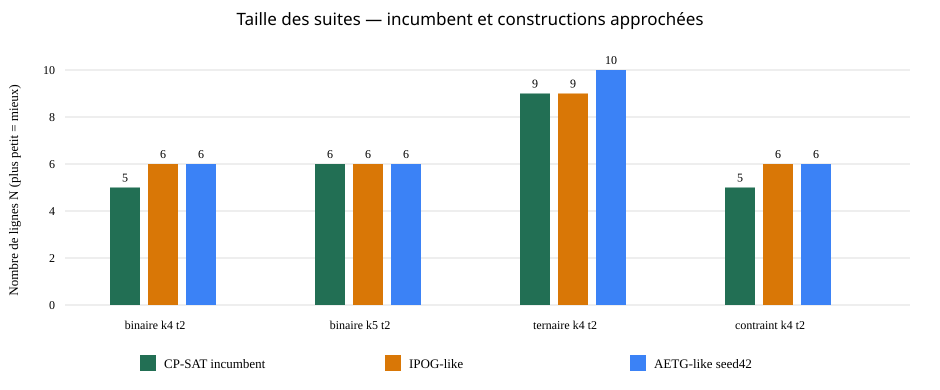

Figure SVG opaque : les trois suites sont auditées, leurs tailles restent distinctes des preuves d'optimalité.


In [10]:
#nullable enable
// Enveloppe d'affichage : le formatter ci-dessous declare le type MIME exact du contenu SVG.
record CoverSvg(string Content);
// image/svg+xml (et non text/html) : seul ce MIME rend la figure comme image, pas comme page.
// API courante : FormatDelegate (retour bool) puis mime preferee explicite pour display().
Formatter.Register<CoverSvg>((v, ctx) => { ctx.Writer.Write(v.Content); return true; }, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(CoverSvg), new[] { "image/svg+xml" });

string Escape(string s) => WebUtility.HtmlEncode(s);

// Figure : trois barres par instance (CP-SAT, IPOG-like, AETG-like) sur une echelle verticale commune.
var svg = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='940' height='390' viewBox='0 0 940 390'><rect width='940' height='390' fill='white'/><text x='470' y='25' text-anchor='middle' font-family='sans-serif' font-size='17'>Taille des suites — incumbent et constructions approchées</text>");
int ymax = Math.Max(1, bench.Max(b => Math.Max(b.Exact.N ?? 0, Math.Max(b.Ipo.Length, b.Aetg.Length))));
double Y(double v) => 305 - 235 * v / ymax;

// Graduations horizontales : l'echelle est celle de la plus grande suite du banc.
for (int tick = 0; tick <= ymax; tick += Math.Max(1, ymax / 5))
{
    double y = Y(tick);
    svg.Append($"<line x1='65' y1='{y:F2}' x2='910' y2='{y:F2}' stroke='#ddd'/><text x='55' y='{y+4:F2}' text-anchor='end' font-size='12'>{tick}</text>");
}

// Une barre par construction : un ? signale un incumbent absent, jamais un zero.
string[] colors = { "#226f54", "#d97706", "#3b82f6" };
for (int i = 0; i < bench.Count; i++)
{
    var b = bench[i];
    int[] values = { b.Exact.N ?? 0, b.Ipo.Length, b.Aetg.Length };
    for (int j = 0; j < 3; j++)
    {
        double x = 110 + i * 205 + j * 38;
        svg.Append($"<rect x='{x}' y='{Y(values[j]):F2}' width='30' height='{305-Y(values[j]):F2}' fill='{colors[j]}'/><text x='{x+15}' y='{Y(values[j])-6:F2}' text-anchor='middle' font-size='12'>{(j==0&&b.Exact.N is null?"?":values[j].ToString())}</text>");
    }
    svg.Append($"<text x='{155+i*205}' y='329' text-anchor='middle' font-size='12'>{Escape(b.Name)}</text>");
}

// Axe vertical et legende.
svg.Append("<text transform='translate(18 190) rotate(-90)' text-anchor='middle' font-size='13'>Nombre de lignes N (plus petit = mieux)</text>");
string[] labels = { "CP-SAT incumbent", "IPOG-like", "AETG-like seed42" };
for (int j = 0; j < 3; j++)
    svg.Append($"<rect x='{140+j*245}' y='355' width='16' height='16' fill='{colors[j]}'/><text x='{164+j*245}' y='368' font-size='13'>{labels[j]}</text>");
svg.Append("</svg>");

display(new CoverSvg(svg.ToString()));
Console.WriteLine("Figure SVG opaque : les trois suites sont auditées, leurs tailles restent distinctes des preuves d'optimalité.");


Une barre plus haute indique des tests supplémentaires. Une barre au niveau de l'incumbent peut retrouver l'optimum si la borne est fermée, ou seulement la meilleure taille observée si le statut demeure faisable. La couverture vient de l'oracle ; la minimalité vient d'un minorant valide atteint. Pour le cas ternaire, le comptage $3^2=9$ suffit même si la borne du solveur reste ouverte.

### Exercice 3 — Sensibilité aux graines

Pour les graines zéro à dix-neuf, appelez le constructeur fourni et retournez les vingt tailles de l'instance ternaire. Le contrôleur observe les appels par graine et compare la réponse aux suites réellement construites. Il ne certifie pas une liste de tailles déclarée sans exécution.

In [11]:
#nullable enable
// Exercice 3 : observer vingt graines du glouton sur l'instance ternaire.
int[]? SeedSweep(Func<int, int> build)
{
    return null; /* TODO etudiant : appeler build(s) pour s=0..19 et conserver les tailles. */
}

// Garde de l'exercice : les vingt tailles doivent venir de vingt constructions reelles et couvrantes.
int[]? CheckSeedSweep(Func<Func<int, int>, int[]?> student)
{
    var seen = new Dictionary<int, int>();
    var ternary = Enumerable.Range(0, 4).Select(_ => new[] { 0, 1, 2 }).ToArray();
    int Observed(int seed)
    {
        if (seed < 0 || seed >= 20) throw new ArgumentException("Graine hors0..19");
        var suite = GreedyCover(ternary, 2, seed: seed);
        var a = Audit(suite, Interactions(ternary, 2));
        if (!a.Valid) throw new Exception("Suite non couvrante");
        seen[seed] = suite.Length;
        return suite.Length;
    }
    var response = student(Observed);
    if (response is null && seen.Count == 0) return null;
    if (response is null || response.Length != 20 || seen.Count != 20 || Enumerable.Range(0, 20).Any(s => response[s] != seen[s]))
        throw new ArgumentException("Vingt appels réels et leurs vingt tailles requises");
    return response;
}

var seedSizes = CheckSeedSweep(SeedSweep);
if (seedSizes is null)
    Console.WriteLine("Exercice 3 à compléter : vingt graines observées, tailles puis distribution.");
else
{
    var sizes = seedSizes;
    foreach (var g in sizes.GroupBy(x => x).OrderBy(g => g.Key))
        Console.WriteLine($"N={g.Key}: {g.Count()} graines");
    Console.WriteLine("Le minimum observé est une borne supérieure ; comparer au statut exact.");

    // Histogramme des tailles observees, meme enveloppe SVG que la figure precedente.
    var groups = sizes.GroupBy(x => x).OrderBy(g => g.Key).ToArray();
    var chart = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='340' viewBox='0 0 700 340'><rect width='700' height='340' fill='white'/><text x='350' y='25' text-anchor='middle'>Sensibilité AETG-like — vingt graines</text><line x1='65' y1='270' x2='665' y2='270' stroke='black'/><line x1='65' y1='50' x2='65' y2='270' stroke='black'/><text x='350' y='325' text-anchor='middle'>Taille de suite N</text><text transform='translate(20 160) rotate(-90)' text-anchor='middle'>Nombre de graines</text>");
    for (int tick = 0; tick <= 20; tick += 5)
    {
        double y = 270 - 10 * tick;
        chart.Append($"<text x='55' y='{y+4}' text-anchor='end'>{tick}</text><line x1='65' y1='{y}' x2='665' y2='{y}' stroke='#ddd'/>");
    }
    for (int i = 0; i < groups.Length; i++)
    {
        double x = 100 + i * 520.0 / groups.Length;
        double height = 10 * groups[i].Count();
        chart.Append($"<rect x='{x:F2}' y='{270-height:F2}' width='{Math.Min(80,400.0/groups.Length):F2}' height='{height:F2}' fill='#3b82f6'/><text x='{x+20:F2}' y='292' text-anchor='middle'>{groups[i].Key}</text><text x='{x+20:F2}' y='{265-height:F2}' text-anchor='middle'>{groups[i].Count()}</text>");
    }
    chart.Append("</svg>");
    display(new CoverSvg(chart.ToString()));
}


Exercice 3 à compléter : vingt graines observées, tailles puis distribution.


Les contrôles portent sur les expériences demandées, pas sur l'esthétique du code étudiant. Une réponse correcte peut naturellement renvoyer plusieurs tailles identiques ; elle doit cependant provenir des vingt appels observés. Le minimum des graines n'est jamais une borne inférieure.

## 6. Lire un time-out sans inventer une mesure

L'incertitude se lit $\mathrm{borne}\le N^*\le\mathrm{incumbent}$. Le cas suivant reprend un vrai run, puis fabrique explicitement **une fiche de lecture synthétique**, sans inventer de sortie de solveur.

Cette lecture utilise seulement les champs du solveur. Une borne indépendante peut compléter sa preuve : le cas ternaire atteint le minorant combinatoire neuf, tout en conservant le statut réel `FEASIBLE`.

In [12]:
#nullable enable
// Formuler une preuve : un statut, une taille et une borne ne disent pas la meme chose.
string Evidence(string status, int? n, double? bound)
{
    if (status == "OPTIMAL") return $"optimum certifié N={n} (borne={bound})";
    if (status == "FEASIBLE") return $"solution N={n}, optimum inconnu dans [{bound},{n}]";
    return $"aucune solution certifiée ({status})";
}

// Run reel sur k5, puis la meme preuve formulee pour un cas FEASIBLE : la difference est le propos du carnet.
var certified = SolveExact(Enumerable.Range(0, 5).Select(_ => new[] { 0, 1 }).ToArray(), 2, timeLimit: 15);
Console.WriteLine("Run réel : " + Evidence(certified.Status, certified.N, certified.Bound));
Console.WriteLine("Fiche synthétique FEASIBLE : " + Evidence("FEASIBLE", certified.N + 2, certified.Bound));
Console.WriteLine("Interdit : présenter un incumbent comme optimal quand la borne reste ouverte.");


Run réel : optimum certifié N=6 (borne=6)


Fiche synthétique FEASIBLE : solution N=8, optimum inconnu dans [6,8]


Interdit : présenter un incumbent comme optimal quand la borne reste ouverte.


La seconde ligne n'est pas un run chronométré : son statut et sa taille sont volontairement modifiés pour enseigner la lecture d'un intervalle. Le véritable résultat conserve sa borne et son statut au-dessus.

## 7. Limites honnêtes

| Objet | Ce qu'il établit | Sa limite |
|---|---|---|
| Oracle | couverture de l'univers fourni | ni minimalité ni justesse des règles métier |
| Incumbent | existence d'une suite | aucune borne inférieure |
| OPTIMAL et borne fermée | optimum du modèle fini | aucune formule générale de CAN(t,k,v) |
| IPOG-like/AETG-like | gloutons de référence locaux | pas les implémentations industrielles |
| Graine fixe | répétabilité dans cet environnement | pas robustesse à toutes les graines |
| Quatre petits benchmarks | comparaison bornée | pas classement universel |

Le set cover énumère toutes les lignes candidates, donc son coût croît avec le produit des tailles des domaines. Le modèle à slots du projet étudiant vise une autre échelle. Les chronométrages ne comparent pas les langages : versions, algorithmes internes et machines diffèrent.

## À retenir

- Une ligne ne couvre qu'un sous-ensemble d'interactions : la borne quatre du cas binaire à quatre facteurs n'est pas atteinte ; l'exact certifie cinq.
- La force trois fournit un contrôle positif où la borne huit est atteinte.
- Les règles sémantiques passent de vingt-quatre interactions cartésiennes à vingt-deux interactions exigibles sur neuf lignes admissibles.
- Validité, borne supérieure et minimalité correspondent à trois preuves différentes ; le minorant combinatoire neuf certifie aussi le témoin ternaire à neuf, sans changer le statut solveur.
- Le protocole ne transforme ni un tie-break semé ni un time-out en théorème.

## Vérifiez votre compréhension

1. Pourquoi quatre lignes ne suffisent-elles pas alors que la borne de comptage vaut quatre ?
2. Pourquoi le validateur naïf déclare-t-il deux interactions absentes sur la suite contrainte ?
3. Deux barres de même hauteur prouvent-elles l'optimalité ?

<details><summary>Réponses</summary>

1. Le comptage ignore la compatibilité des couvertures entre paires ; CP-SAT ferme la borne à cinq sur le modèle fini.
2. Il exige l'univers cartésien, contenant deux interactions sans extension admissible. L'oracle conscient exige seulement les vingt-deux faisables.
3. Non. Il faut un témoin valide et un minorant de même taille. Le solveur peut fournir ce minorant, mais le comptage le fournit aussi dans le cas ternaire : neuf lignes couvrantes et $N^*\ge9$ certifient neuf sans statut solveur `OPTIMAL`.

</details>

## Pour aller plus loin

- [Frontieres-03 — MAPF](Frontieres-03-MAPF-Guarantee-Audit-Python.ipynb) : solution valide, optimum observé et garantie d'un algorithme.
- [Frontieres-06 — Learning to Branch](Frontieres-06-LearningToBranch-Generalization-Audit-Python.ipynb) : mesurer la généralisation d'un ordre appris.
- [CSP-5 — optimisation](../Part2-CSP/CSP-5-Optimization.ipynb) : incumbent et borne.
- Le geste source : [H4 Covering Arrays](https://github.com/jsboigeEpita/2026-Epita-Programmation-par-Contraintes/tree/main/H4-Covering-Arrays), Valérian Pichot, MIT ; documentation [Google OR-Tools CP-SAT](https://developers.google.com/optimization/cp/cp_solver).